<a href="https://colab.research.google.com/github/njoh0025/MMA3001-Nicholas-Johnson/blob/main/Nicholas_Johnson_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import LabelEncoder
import time

start_time = time.time()

files = ['Pre Daylight Savings.xlsx', 'Post Daylight Savings.xlsx']
dfs = []

for file_name in files:
    print(f"Loading Excel file: {file_name}...")
    excel_file = pd.ExcelFile(file_name)
    sheet_name = excel_file.sheet_names[0]
    temp_df = excel_file.parse(sheet_name)

    # If temp_df is empty, try reading and skipping empty rows at the top
    if temp_df.empty or len(temp_df.columns) == 0:
        print(f"First parse attempt for {file_name} was empty. Attempting to locate the header row automatically...")
        for skiprows in range(1, 10):
            temp_df = excel_file.parse(sheet_name, skiprows=skiprows)
            if not temp_df.empty and len(temp_df.columns) > 0:
                break

    # Clean column names
    temp_df.columns = temp_df.columns.astype(str).str.replace('"', '', regex=False).str.strip()

    # Case-insensitive column mapping helper
    col_map = {c.lower().replace(" ", "").replace("_", ""): c for c in temp_df.columns}

    target_cols = {
        'collecteddate': col_map.get('collecteddate'),
        'floorspaceid': col_map.get('floorspaceid'),
        'headcount': col_map.get('headcount')
    }

    for standard_name, mapped_name in target_cols.items():
        if mapped_name is None:
            for col in temp_df.columns:
                clean_col = col.lower().replace(" ", "").replace("_", "")
                if standard_name in clean_col:
                    target_cols[standard_name] = col
                    break

    missing = [k for k, v in target_cols.items() if v is None]
    if missing:
        raise KeyError(f"Could not find suitable columns in {file_name} for: {missing}.")

    temp_df = temp_df.rename(columns={v: k for k, v in target_cols.items() if v is not None})
    dfs.append(temp_df)

# Combine datasets
df = pd.concat(dfs, ignore_index=True)
print("Combined dataset size:", df.shape[0])

# Clean string values in the dataset
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.replace('"', '', regex=False).str.strip()

df['headcount'] = pd.to_numeric(df['headcount'], errors='coerce')
df = df.dropna(subset=['collecteddate', 'floorspaceid', 'headcount'])

# 2. Date-Time Preprocessing with local timezone conversion for Victoria, Australia (Australia/Melbourne)
print("Parsing dates and converting to Australia/Melbourne timezone...")
# Parse to UTC first to handle mixed offsets properly
df['collecteddate'] = pd.to_datetime(df['collecteddate'], errors='coerce', utc=True)
df = df.dropna(subset=['collecteddate'])

# Convert to Victoria, Australia local timezone
df['collecteddate_local'] = df['collecteddate'].dt.tz_convert('Australia/Melbourne')

# Extract temporal features in local time
df['timestamp'] = df['collecteddate'].astype(np.int64) // 10**9
df['hour'] = df['collecteddate_local'].dt.hour
df['dayofweek'] = df['collecteddate_local'].dt.dayofweek

# Encode rooms
le = LabelEncoder()
df['floorspaceid_encoded'] = le.fit_transform(df['floorspaceid'])

# Define features and target
features = ['floorspaceid_encoded', 'timestamp', 'hour', 'dayofweek']
target = 'headcount'

# Split data
validation_mask = df.index % 5 == 0
train_df = df[~validation_mask]
val_df = df[validation_mask]

X_train = train_df[features]
y_train = train_df[target]
X_val = val_df[features]
y_val = val_df[target]

# 3. Fast Machine Learning Model
print("Training model (HistGradientBoosting)...")
model = HistGradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

# Evaluate
predictions = model.predict(X_val)
mse = mean_squared_error(y_val, predictions)
print(f"\nValidation Mean Squared Error: {mse:.4f}")

# Room-wise statistics
room_trends = (
    df.groupby('floorspaceid')['headcount'].agg(['mean', 'max', 'min']).reset_index()
)
print("\nRoom-wise Headcount Statistics:")
print(room_trends)

print(f"\nExecution finished in {time.time() - start_time:.2f} seconds!")

Loading Excel file: Pre Daylight Savings.xlsx...
Loading Excel file: Post Daylight Savings.xlsx...
Combined dataset size: 1048575
Parsing dates and converting to Australia/Melbourne timezone...
Training model (HistGradientBoosting)...

Validation Mean Squared Error: 2.5879

Room-wise Headcount Statistics:
                           floorspaceid      mean  max  min
0  0f3f37f8-0335-41e0-ae87-a1d677dfc7d7  2.196044   25    0
1  227f1068-9e41-469f-bef0-275f27a0bdba  4.105876   38    0
2  3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8  7.432215   25    0
3  941f0352-bb69-47d0-a9c5-ac29eb4f7319  2.319945   14    0
4  cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b  3.073506   49    0

Execution finished in 143.78 seconds!


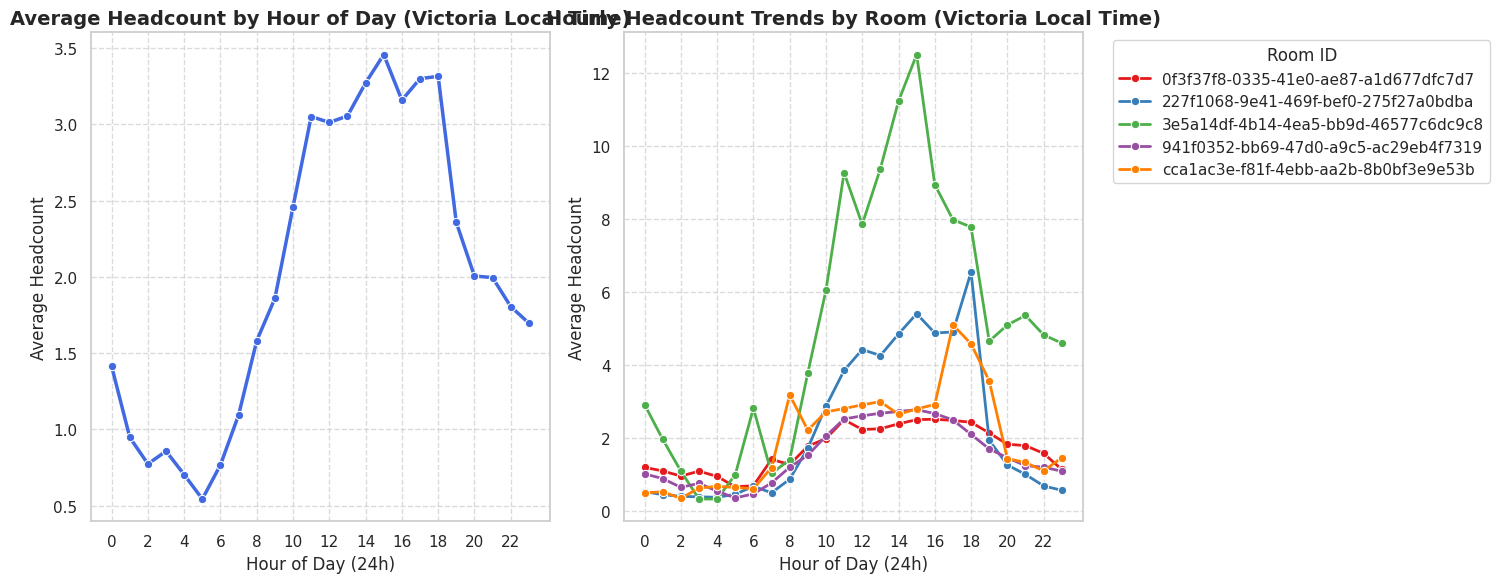

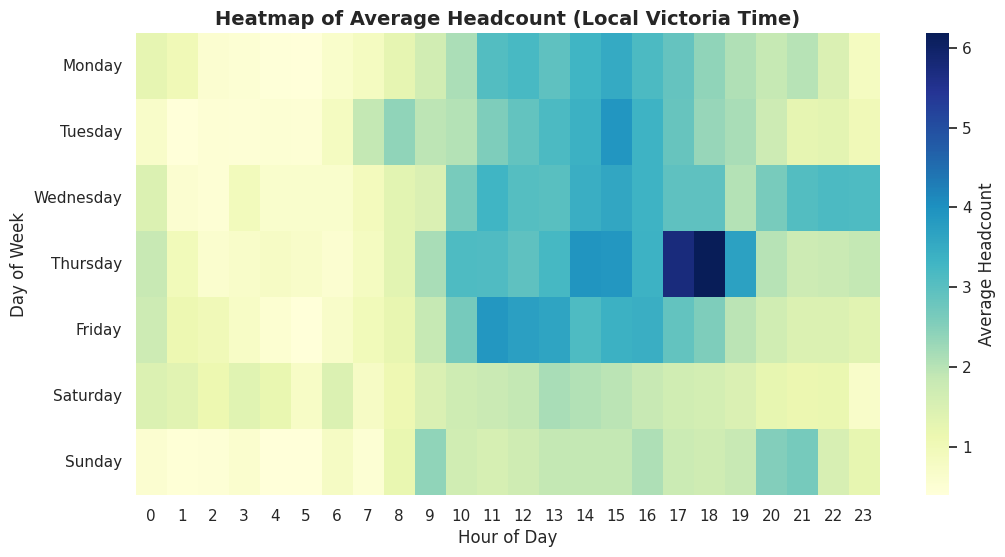

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 6))

# 1. Hourly Headcount Profile in Victoria Local Time
plt.subplot(1, 2, 1)
hourly_trends = df.groupby('hour')['headcount'].mean().reset_index()
sns.lineplot(data=hourly_trends, x='hour', y='headcount', marker='o', color='royalblue', linewidth=2.5)
plt.title('Average Headcount by Hour of Day (Victoria Local Time)', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (24h)', fontsize=12)
plt.ylabel('Average Headcount', fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(True, linestyle='--', alpha=0.7)

# 2. Hourly Profile broken down by Room in Victoria Local Time
plt.subplot(1, 2, 2)
room_hourly = df.groupby(['hour', 'floorspaceid'])['headcount'].mean().reset_index()
sns.lineplot(data=room_hourly, x='hour', y='headcount', hue='floorspaceid', marker='o', palette='Set1', linewidth=2)
plt.title('Hourly Headcount Trends by Room (Victoria Local Time)', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (24h)', fontsize=12)
plt.ylabel('Average Headcount', fontsize=12)
plt.xticks(range(0, 24, 2))
plt.legend(title='Room ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 3. Weekly Heatmap (Hour vs Day of Week in Victoria Local Time)
plt.figure(figsize=(12, 6))
pivot_table = df.pivot_table(values='headcount', index='dayofweek', columns='hour', aggfunc='mean')
day_labels = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_table.index = [day_labels[i] for i in pivot_table.index]

sns.heatmap(pivot_table, cmap='YlGnBu', annot=False, cbar_kws={'label': 'Average Headcount'})
plt.title('Heatmap of Average Headcount (Local Victoria Time)', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.show()

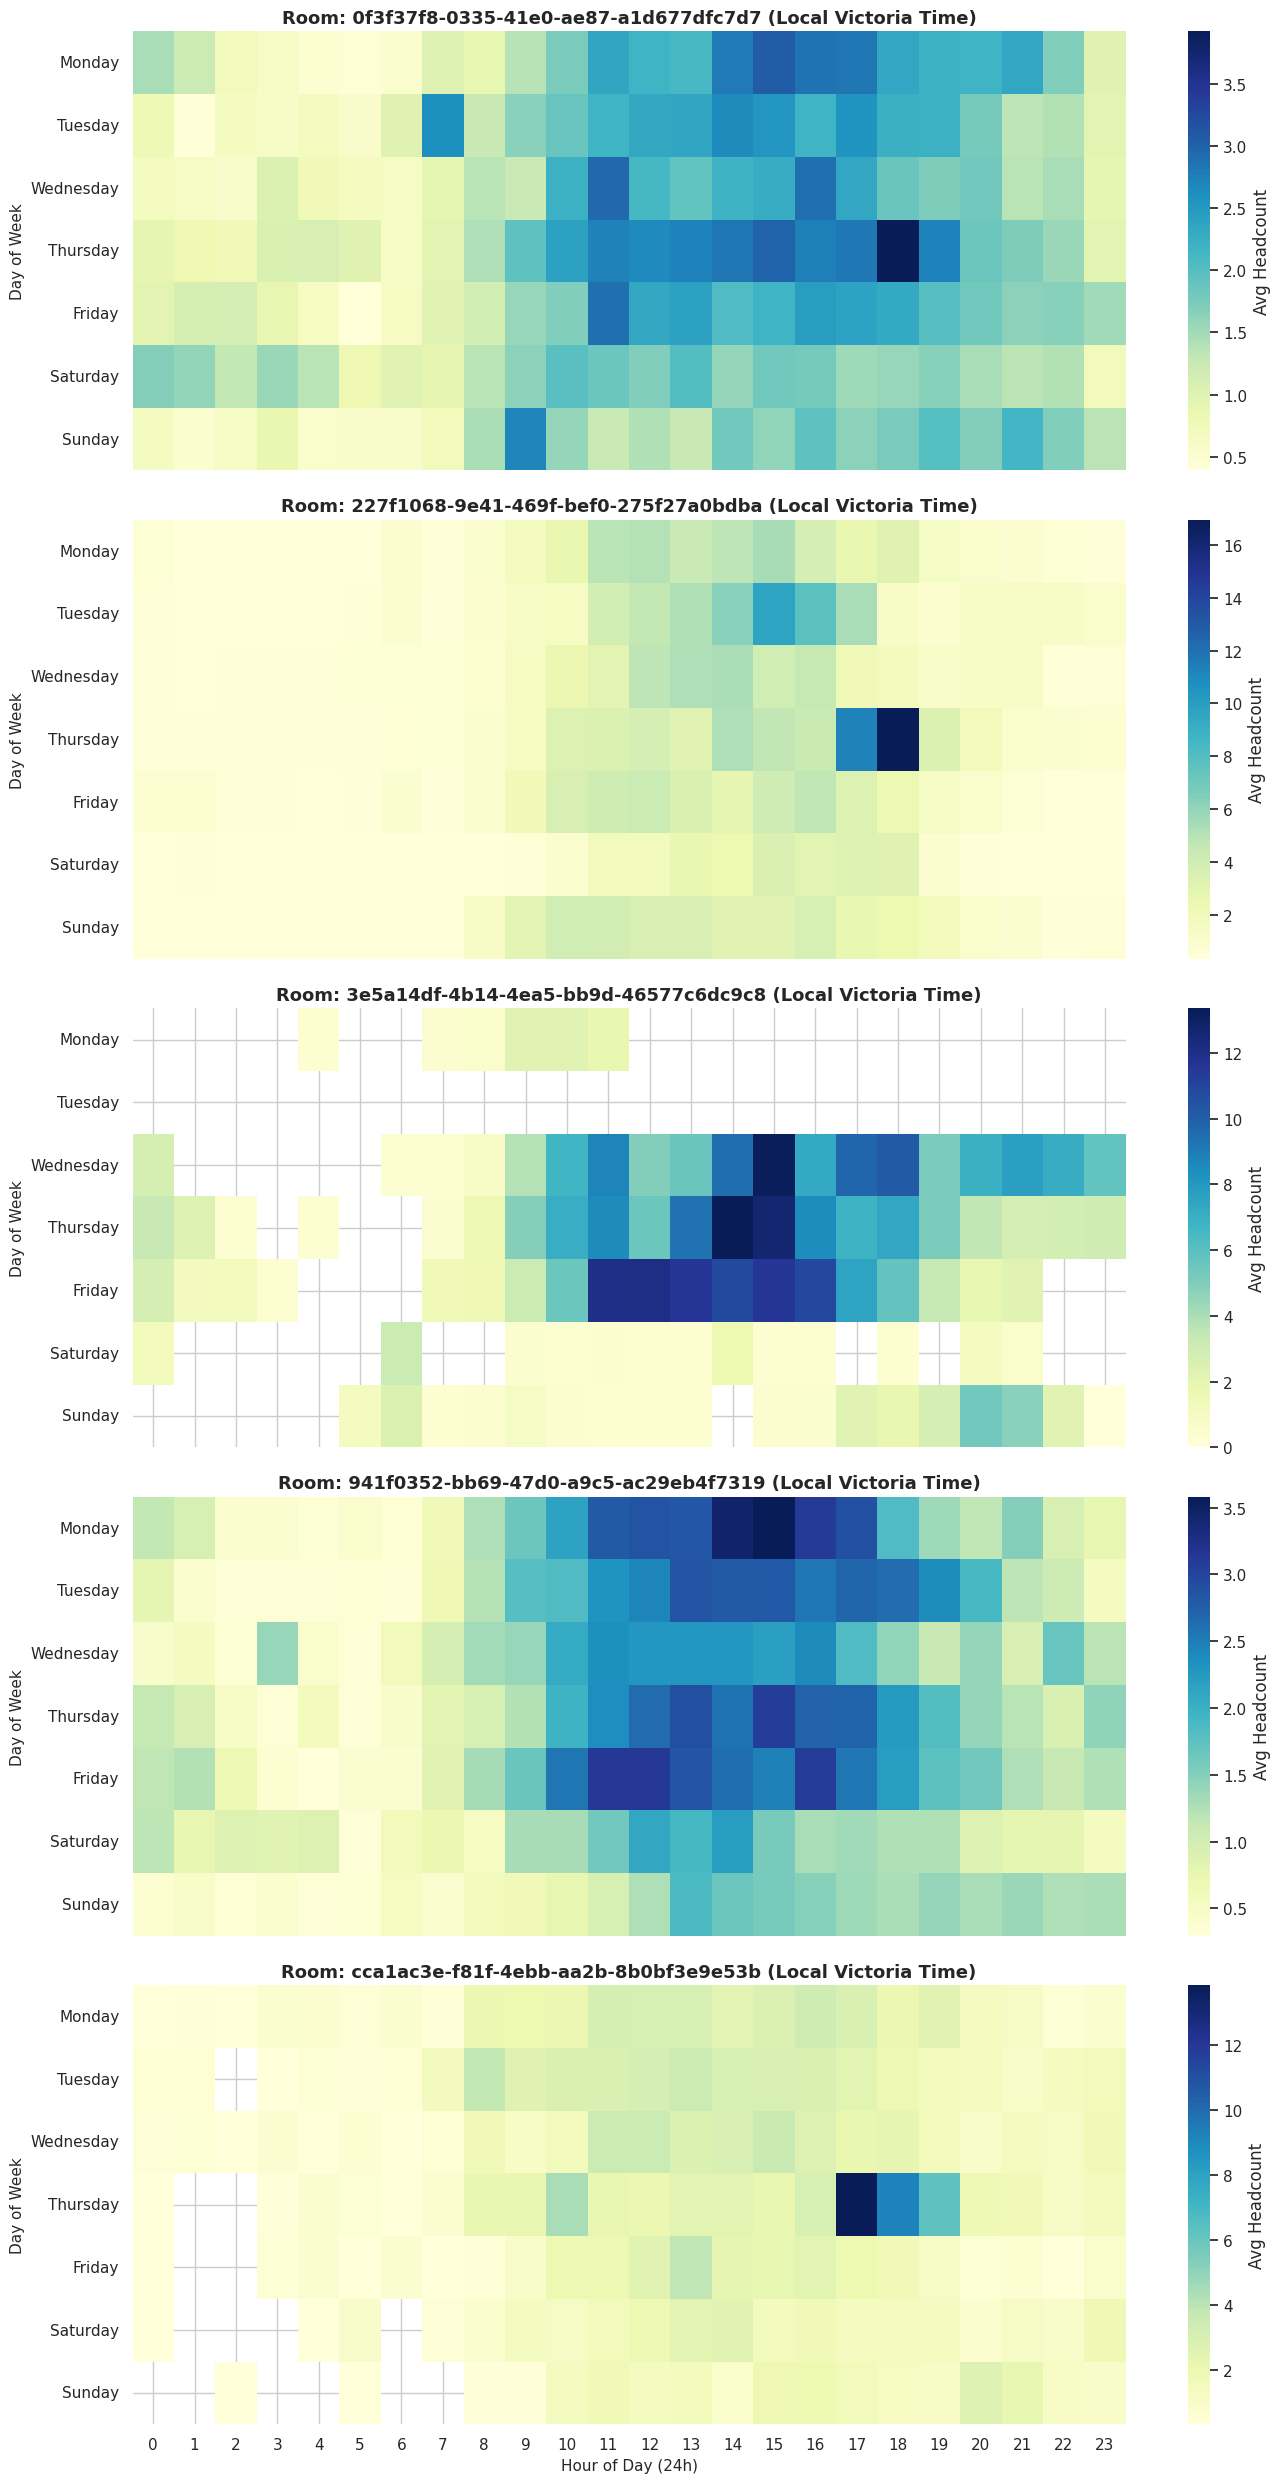

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the list of unique floor spaces
rooms = df['floorspaceid'].unique()
num_rooms = len(rooms)

# Create a grid of subplots for each room
fig, axes = plt.subplots(num_rooms, 1, figsize=(14, 5 * num_rooms), sharex=True)
if num_rooms == 1:
    axes = [axes]

day_labels = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

for idx, room_id in enumerate(sorted(rooms)):
    room_df = df[df['floorspaceid'] == room_id]

    # Generate pivot table for this specific room
    pivot_room = room_df.pivot_table(
        values='headcount',
        index='dayofweek',
        columns='hour',
        aggfunc='mean'
    )

    # Align index with standard day labels
    pivot_room = pivot_room.reindex(range(7))
    pivot_room.index = day_labels

    # Plot heatmap on corresponding subplot axis
    ax = axes[idx]
    sns.heatmap(
        pivot_room,
        cmap='YlGnBu',
        annot=False,
        cbar_kws={'label': 'Avg Headcount'},
        ax=ax
    )
    ax.set_title(f'Room: {room_id} (Local Victoria Time)', fontsize=13, fontweight='bold')
    ax.set_ylabel('Day of Week', fontsize=11)
    if idx == num_rooms - 1:
        ax.set_xlabel('Hour of Day (24h)', fontsize=11)
    else:
        ax.set_xlabel('')

plt.tight_layout()
plt.show()

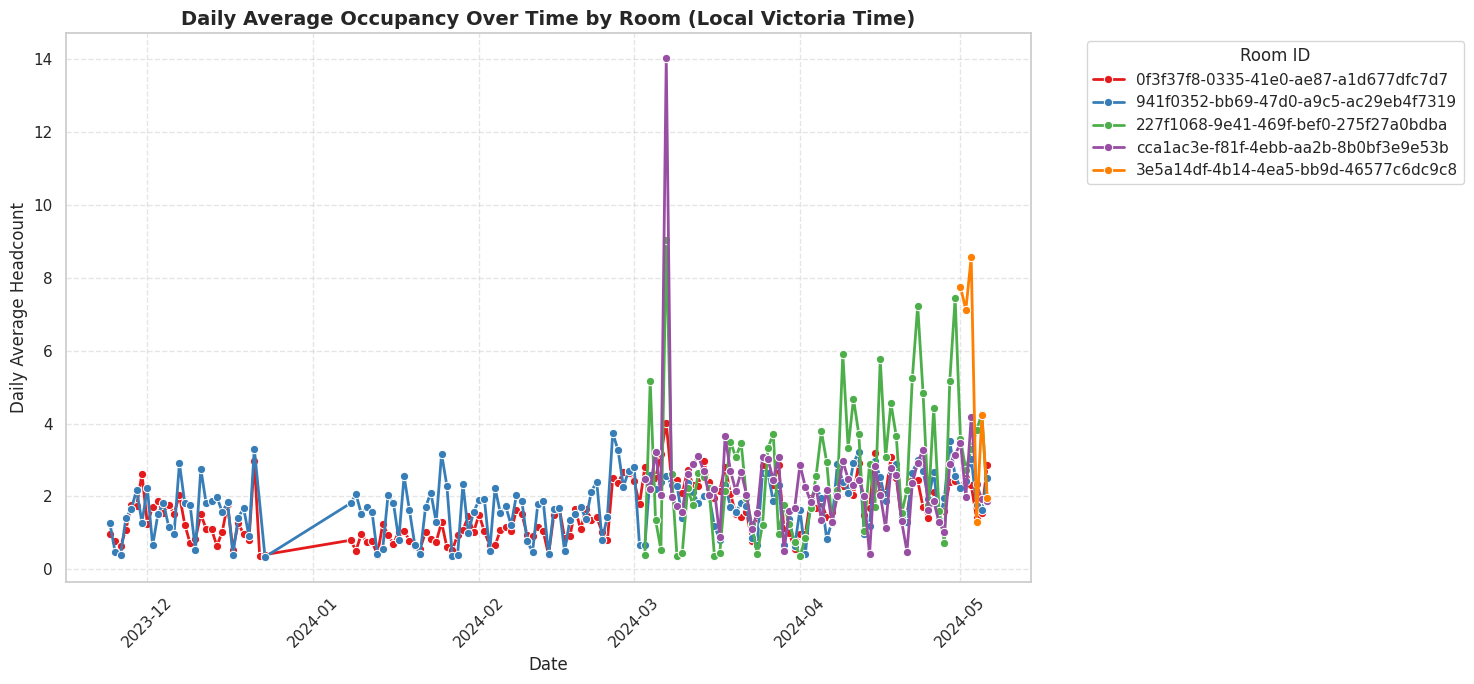

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract the date in local Victoria time
df['date_local'] = df['collecteddate_local'].dt.date

# Calculate the daily average headcount per room
daily_room_occupancy = df.groupby(['date_local', 'floorspaceid'])['headcount'].mean().reset_index()

# Plot the line graph
plt.figure(figsize=(15, 7))
sns.lineplot(
    data=daily_room_occupancy,
    x='date_local',
    y='headcount',
    hue='floorspaceid',
    marker='o',
    palette='Set1',
    linewidth=2
)

plt.title('Daily Average Occupancy Over Time by Room (Local Victoria Time)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Daily Average Headcount', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.legend(title='Room ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [21]:
import os

target_file = '5occupancySensor_MayToDec2024_9MRows.csv'

if not os.path.exists(target_file):
    print(f"Could not find the original master file: {target_file}")
else:
    file_name, file_ext = os.path.splitext(target_file)
    print(f"Processing Master File: {target_file}")

    chunk_size = 1000000

    print("Using direct line-by-line split to bypass CSV quoting errors...")
    with open(target_file, 'r', encoding='utf-8', errors='ignore') as infile:
        # Read the header row
        header = infile.readline()

        chunk_idx = 1
        line_count = 0
        outfile = open(f"{file_name}_part_{chunk_idx}.csv", 'w', encoding='utf-8')
        outfile.write(header)

        for line in infile:
            outfile.write(line)
            line_count += 1

            if line_count == chunk_size:
                print(f"Saved {file_name}_part_{chunk_idx}.csv ({line_count} rows)")
                outfile.close()
                chunk_idx += 1
                line_count = 0
                outfile = open(f"{file_name}_part_{chunk_idx}.csv", 'w', encoding='utf-8')
                outfile.write(header)

        # Close the last file if it has written lines
        outfile.close()
        if line_count == 0:
            # Remove empty file if splitting finished on perfect boundary
            os.remove(f"{file_name}_part_{chunk_idx}.csv")
        else:
            print(f"Saved {file_name}_part_{chunk_idx}.csv ({line_count} rows)")

Could not find the original master file: 5occupancySensor_MayToDec2024_9MRows.csv


In [22]:
# Calculate standard deviation of headcount for each of the 5 rooms
room_std = df.groupby('floorspaceid')['headcount'].std().reset_index()
room_std.columns = ['floorspaceid', 'headcount_std']

# Display the results
display(room_std)

,floorspaceid,headcount_std
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,1.710558
1,227f1068-9e41-469f-bef0-275f27a0bdba,3.854917
2,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8,4.055343
3,941f0352-bb69-47d0-a9c5-ac29eb4f7319,1.509078
4,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b,3.600397
